# 04 Evaluation and error analysis
Turns the backtest into a story: how much better is the model, is it stable, where does it win and lose, and what does it mean for the business.
Needs `reports/results_per_series.parquet`, saved by notebook 03.

In [1]:
import sys
sys.path.append("..")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

REP, FIG = Path("../reports"), Path("../reports/figures")
H = 28

res = pd.read_parquet(REP / "results_per_series.parquet")
res["abs_err_sum"] = res["mae"] * H
res["fc_sum"] = res["bias"] * H + res["actual_sum"]
ok = res.dropna(subset=["rmsse"]).copy()
ok["wr"] = ok["rmsse"] * ok["weight"]

classes = res.drop_duplicates("id").set_index("id")["class"]
print(res["model"].unique(), "|", res["id"].nunique(), "series |", res["fold"].nunique(), "folds")

<ArrowStringArray>
['lightgbm', 'ma_28', 'dow_mean_4w', 'tsb']
Length: 4, dtype: str | 3049 series | 5 folds


## 1. Headline table
- **wrmsse**: revenue-weighted RMSSE (the M5-style score, lower is better)
- **wape_%**: total absolute error / total actual units, at item-store level
- **bias_%**: net over (+) or under (-) forecasting of total units

In [2]:
gm = ok.groupby("model")
gr = res.groupby("model")
headline = pd.DataFrame({
    "wrmsse": gm["wr"].sum() / gm["weight"].sum(),
    "wape_%": 100 * gr["abs_err_sum"].sum() / gr["actual_sum"].sum(),
    "bias_%": 100 * (gr["fc_sum"].sum() - gr["actual_sum"].sum()) / gr["actual_sum"].sum(),
}).sort_values("wrmsse").round(3)

best = headline.drop("lightgbm").index[0]       # best baseline by wrmsse
gain = (headline.loc["lightgbm", "wrmsse"] / headline.loc[best, "wrmsse"] - 1) * 100
print(f"best baseline: {best} | LightGBM weighted RMSSE change vs it: {gain:+.1f}%")
headline

best baseline: tsb | LightGBM weighted RMSSE change vs it: -3.0%


,wrmsse,wape_%,bias_%
model,,,
lightgbm,0.808,75.526,-3.787
tsb,0.833,75.291,-1.675
ma_28,0.835,75.477,-3.638
dow_mean_4w,0.868,77.393,-3.638


## 2. Store-level view
Item-level forecasts are noisy by nature. What matters operationally is often the total: how close is the 28-day store demand forecast?

In [3]:
tot = res.groupby(["model", "fold"]).agg(fc=("fc_sum", "sum"), act=("actual_sum", "sum"))
tot["abs_pct_err"] = 100 * (tot["fc"] - tot["act"]).abs() / tot["act"]
store_level = tot["abs_pct_err"].unstack("fold").round(2)
store_level["mean"] = store_level.mean(axis=1).round(2)
store_level.loc[headline.index]

fold,0,1,2,3,4,mean
model,,,,,,
lightgbm,6.01,5.95,2.57,0.96,5.51,4.20
tsb,4.06,2.02,0.28,0.57,2.70,1.93
ma_28,5.87,3.87,1.91,2.12,4.53,3.66
dow_mean_4w,5.87,3.87,1.91,2.12,4.53,3.66


## 3. Stability across folds

fold,0,1,2,3,4
model,,,,,
lightgbm,0.804,0.814,0.809,0.808,0.804
tsb,0.838,0.830,0.830,0.841,0.827
ma_28,0.847,0.830,0.833,0.835,0.832
dow_mean_4w,0.894,0.867,0.857,0.866,0.860


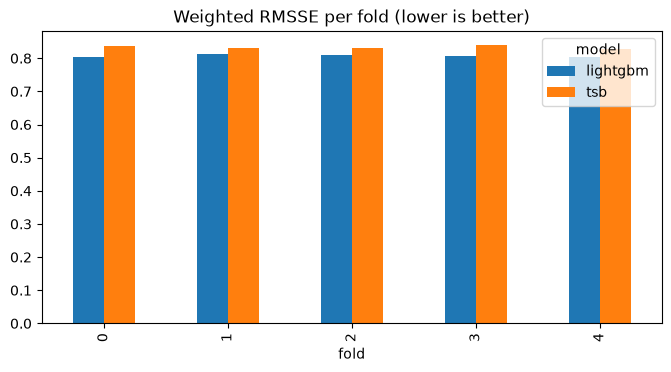

In [4]:
gf = ok.groupby(["model", "fold"])
by_fold = (gf["wr"].sum() / gf["weight"].sum()).unstack("fold")

fig, ax = plt.subplots(figsize=(8, 3.8))
by_fold.loc[["lightgbm", best]].T.plot.bar(ax=ax)
ax.set_title("Weighted RMSSE per fold (lower is better)")
ax.set_xlabel("fold")
fig.savefig(FIG / "08_per_fold.png", dpi=150, bbox_inches="tight")
by_fold.round(3).loc[headline.index]

## 4. Where does LightGBM win?
Per-series paired comparison against the best baseline (mean RMSSE across folds).

,n_series,win_rate,win_rate_revenue_weighted
erratic,82.0,0.622,0.671
intermittent,2192.0,0.555,0.659
lumpy,534.0,0.500,0.572
no sales,2.0,0.500,0.659
smooth,239.0,0.749,0.788
all,3049.0,0.562,0.682


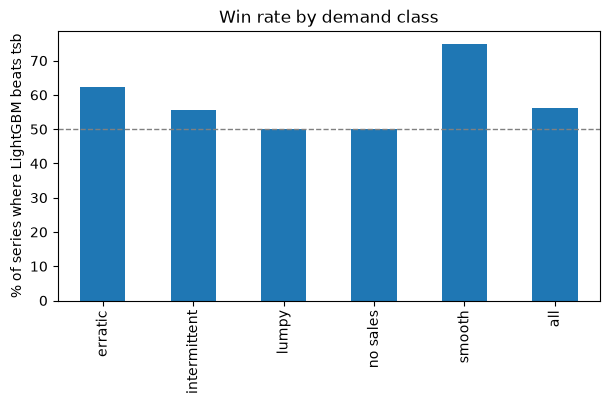

In [5]:
pm = ok.pivot_table(index="id", columns="model", values="rmsse", aggfunc="mean")
wt = ok.groupby("id")["weight"].mean()
pm["win"] = pm["lightgbm"] < pm[best]
pm["class"] = classes
pm["weight"] = wt

def wrate(d):
    return pd.Series({
        "n_series": len(d),
        "win_rate": d["win"].mean(),
        "win_rate_revenue_weighted": np.average(d["win"], weights=d["weight"] + 1e-9),
    })

win_table = pd.concat([
    pm.groupby("class")[["win", "weight"]].apply(wrate),
    wrate(pm).to_frame("all").T,
]).round(3)

fig, ax = plt.subplots(figsize=(7, 3.5))
(win_table["win_rate"] * 100).plot.bar(ax=ax)
ax.axhline(50, color="grey", ls="--", lw=1)
ax.set_ylabel("% of series where LightGBM beats " + best)
ax.set_title("Win rate by demand class")
fig.savefig(FIG / "09_win_rate_by_class.png", dpi=150, bbox_inches="tight")
win_table

## 5. Is the error concentrated?
If a small share of series carries most of the revenue and error, effort should go there first.

top 20% of series by revenue: 62% of revenue, 65% of weighted error


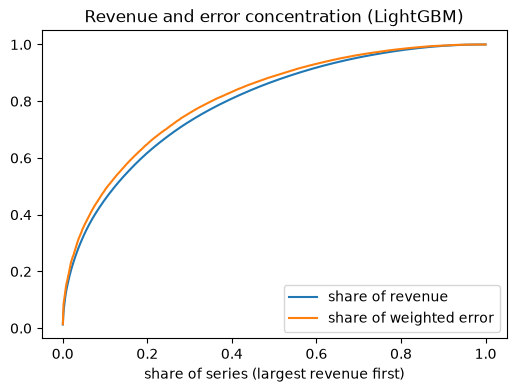

In [6]:
ser = ok[ok["model"] == "lightgbm"].groupby("id").agg(weight=("weight", "mean"), rmsse=("rmsse", "mean"))
ser["werr"] = ser["weight"] * ser["rmsse"]
ser = ser.sort_values("weight", ascending=False)
ser["cum_revenue"] = ser["weight"].cumsum() / ser["weight"].sum()
ser["cum_error"] = ser["werr"].cumsum() / ser["werr"].sum()
x = np.arange(1, len(ser) + 1) / len(ser)

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(x, ser["cum_revenue"].to_numpy(), label="share of revenue")
ax.plot(x, ser["cum_error"].to_numpy(), label="share of weighted error")
ax.set_xlabel("share of series (largest revenue first)")
ax.legend()
ax.set_title("Revenue and error concentration (LightGBM)")
fig.savefig(FIG / "10_error_concentration.png", dpi=150, bbox_inches="tight")

top20 = int(0.2 * len(ser))
print(f"top 20% of series by revenue: {ser['cum_revenue'].iloc[top20 - 1]:.0%} of revenue, "
      f"{ser['cum_error'].iloc[top20 - 1]:.0%} of weighted error")

In [7]:
# the 15 series that hurt most (revenue x error)
worst = ser.sort_values("werr", ascending=False).head(15).join(classes).join(
    res[res["model"] == "lightgbm"].groupby("id").apply(
        lambda d: 100 * (d["fc_sum"].sum() - d["actual_sum"].sum()) / max(d["actual_sum"].sum(), 1e-9),
        include_groups=False,
    ).rename("bias_%")
)
worst[["class", "weight", "rmsse", "bias_%"]].round(2)

,class,weight,rmsse,bias_%
id,,,,
FOODS_3_511_CA_1_evaluation,intermittent,4333.18,1.77,-35.07
FOODS_3_120_CA_1_evaluation,smooth,4656.30,0.96,4.03
HOBBIES_1_354_CA_1_evaluation,intermittent,5087.77,0.86,0.26
HOBBIES_1_241_CA_1_evaluation,intermittent,2943.14,1.33,11.23
HOUSEHOLD_1_032_CA_1_evaluation,smooth,2928.11,1.09,2.32
HOBBIES_1_158_CA_1_evaluation,intermittent,2753.00,1.01,10.56
HOBBIES_1_147_CA_1_evaluation,smooth,1942.16,0.95,-0.89
FOODS_2_029_CA_1_evaluation,intermittent,1524.94,1.08,-14.22
FOODS_3_587_CA_1_evaluation,intermittent,1784.61,0.82,-3.03


## 6. Bias by demand class

In [8]:
gb = res.groupby(["class", "model"])
bias_class = (100 * (gb["fc_sum"].sum() - gb["actual_sum"].sum()) / gb["actual_sum"].sum()).unstack("model").round(1)
bias_class[["lightgbm", best]]

model,lightgbm,tsb
class,,
erratic,-5.1,1.6
intermittent,-1.9,-2.4
lumpy,-1.9,-4.7
no sales,-9.0,-31.2
smooth,-7.4,0.5


## 7. Auto-written results paragraph for the README
Copy it, then adjust the wording to your own voice.

In [9]:
l, b = headline.loc["lightgbm"], headline.loc[best]
sl = store_level.loc["lightgbm", "mean"]
sb = store_level.loc[best, "mean"]
print(f"""On a 5-fold rolling 28-day backtest, a global LightGBM model {'reduced' if gain < 0 else 'increased'} revenue-weighted RMSSE from {b['wrmsse']:.3f} ({best}) to {l['wrmsse']:.3f} ({gain:+.1f}%).
Item-level WAPE {'fell' if l['wape_%'] < b['wape_%'] else 'rose'} from {b['wape_%']:.1f}% to {l['wape_%']:.1f}%, and the 28-day store-level demand forecast was off by {sl:.1f}% on average (vs {sb:.1f}% for {best}).
LightGBM beat the baseline on {win_table.loc['all', 'win_rate']:.0%} of series ({win_table.loc['all', 'win_rate_revenue_weighted']:.0%} revenue-weighted).""")

On a 5-fold rolling 28-day backtest, a global LightGBM model reduced revenue-weighted RMSSE from 0.833 (tsb) to 0.808 (-3.0%).
Item-level WAPE rose from 75.3% to 75.5%, and the 28-day store-level demand forecast was off by 4.2% on average (vs 1.9% for tsb).
LightGBM beat the baseline on 56% of series (68% revenue-weighted).


## Takeaways (fill in)
- Headline result and how stable it is across folds:
- Which demand classes still lose to simple baselines:
- Where the error is concentrated (top series, categories):
- Over/under-forecasting pattern:
- Next steps: tune, more history, hierarchical reconciliation, more stores.